# Обнаружение мошеннических вакансий

Датасет **Fake Job Posting Detection**.

Столбец `fraudulent`:
- `0` — настоящее объявление;
- `1` — мошенническое объявление.

Это задача **классификации**. В качестве модели возьмём логистическую регрессию.


В датасете 17 880 объявлений, из них 866 мошеннических. Из-за дисбаланса классов недостаточно смотреть только на долю правильных ответов: отдельно оценим, какую долю мошеннических объявлений модель обнаруживает и сколько ложных тревог создаёт.

## 1. Библиотеки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


## 2. Чтение данных

In [2]:
from pathlib import Path

file_name = Path("fake_job_postings.csv")

if not file_name.exists():
    from google.colab import files
    uploaded = files.upload()
    file_name = Path(list(uploaded.keys())[0])

data = pd.read_csv(file_name)
data.head()


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [3]:
print("Размер таблицы:", data.shape)
print("\nСтолбцы:")
print(data.columns.tolist())
print("\nТипы данных:")
print(data.dtypes)


Размер таблицы: (17880, 18)

Столбцы:
['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']

Типы данных:
job_id                 int64
title                    str
location                 str
department               str
salary_range             str
company_profile          str
description              str
requirements             str
benefits                 str
telecommuting          int64
has_company_logo       int64
has_questions          int64
employment_type          str
required_experience      str
required_education       str
industry                 str
function                 str
fraudulent             int64
dtype: object


## 3. Обучающая и тестовая выборки

In [4]:
data = data.dropna(subset=["fraudulent"])

X = data.drop(columns=["fraudulent", "job_id"], errors="ignore")
y = data["fraudulent"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)


Обучающая выборка: (14304, 16)
Тестовая выборка: (3576, 16)


20% данных для итоговой проверки. `stratify=y` сохраняет одинаковое соотношение настоящих и мошеннических объявлений в обеих выборках.

## 4. Классы и основные характеристики

Количество объявлений каждого класса:
fraudulent
0    17014
1      866
Name: count, dtype: int64


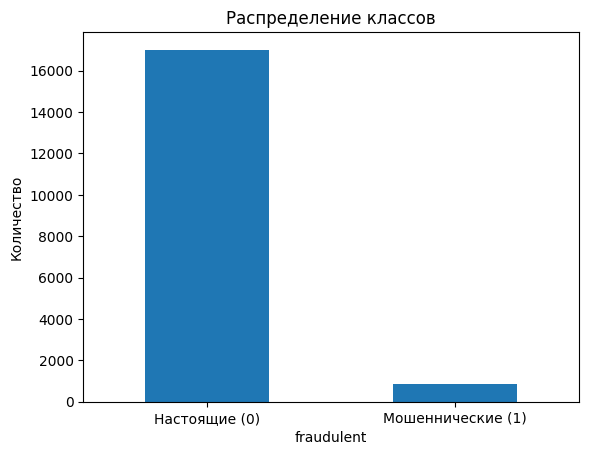

In [5]:
print("Количество объявлений каждого класса:")
print(data["fraudulent"].value_counts())

(data["fraudulent"].value_counts().sort_index()).plot(kind="bar", rot=0)
plt.xticks([0, 1], ["Настоящие (0)", "Мошеннические (1)"])
plt.ylabel("Количество")
plt.title("Распределение классов")
plt.show()


В датасете 17 880 вакансий, из них 17 014 настоящих и 866 мошеннических. Мошеннических объявлений около 4,84%. Классы несбалансированы.

In [6]:
print("Статистика числовых столбцов:")
display(data.select_dtypes(include=np.number).describe().T)

print("\nСамые частые значения некоторых категорий:")
for col in ["employment_type", "required_experience", "required_education", "industry"]:
    if col in data.columns:
        print("\n", col)
        display(data[col].value_counts(dropna=False).head(10))


Статистика числовых столбцов:


,count,mean,std,min,25%,50%,75%,max
job_id,17880.0,8940.500000,5161.655742,1.0,4470.75,8940.5,13410.25,17880.0
telecommuting,17880.0,0.042897,0.202631,0.0,0.00,0.0,0.00,1.0
has_company_logo,17880.0,0.795302,0.403492,0.0,1.00,1.0,1.00,1.0
has_questions,17880.0,0.491723,0.499945,0.0,0.00,0.0,1.00,1.0
fraudulent,17880.0,0.048434,0.214688,0.0,0.00,0.0,0.00,1.0



Самые частые значения некоторых категорий:

 employment_type


employment_type
Full-time    11620
NaN           3471
Contract      1524
Part-time      797
Temporary      241
Other          227
Name: count, dtype: int64


 required_experience


required_experience
NaN                 7050
Mid-Senior level    3809
Entry level         2697
Associate           2297
Not Applicable      1116
Director             389
Internship           381
Executive            141
Name: count, dtype: int64


 required_education


required_education
NaN                                  8105
Bachelor's Degree                    5145
High School or equivalent            2080
Unspecified                          1397
Master's Degree                       416
Associate Degree                      274
Certification                         170
Some College Coursework Completed     102
Professional                           74
Vocational                             49
Name: count, dtype: int64


 industry


industry
NaN                                    4903
Information Technology and Services    1734
Computer Software                      1376
Internet                               1062
Marketing and Advertising               828
Education Management                    822
Financial Services                      779
Hospital & Health Care                  497
Consumer Services                       358
Telecommunications                      342
Name: count, dtype: int64

В основном в этом датасете текстовые и категориальные признаки. Числовые поля вроде `telecommuting`, `has_company_logo` и `has_questions` являются индикаторами: обычно они принимают значения 0 или 1.

## 5. Пропущенные значения

In [7]:
missing = data.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
print("Число пропусков в столбцах:")
print(missing)


Число пропусков в столбцах:
salary_range           15012
department             11547
required_education      8105
benefits                7212
required_experience     7050
function                6455
industry                4903
employment_type         3471
company_profile         3308
requirements            2696
location                 346
description                1
dtype: int64


Больше всего пропусков в `salary_range`: 15 012 значений. В `department` пропущено 11 547 значений. Пропуски в текстовых полях заменим пустой строкой, а в категориальных — самым частым значением.

## 6. Проверим длину описаний и возможные выбросы

count    17880.000000
mean      1218.004418
std        894.828620
min          0.000000
25%        607.000000
50%       1017.000000
75%       1586.000000
max      14907.000000
Name: description, dtype: float64


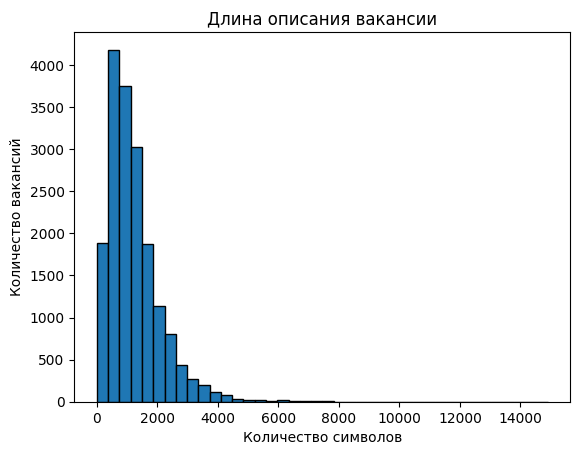

In [8]:
if "description" in data.columns:
    description_length = data["description"].fillna("").str.len()
    print(description_length.describe())

    plt.hist(description_length, bins=40, edgecolor="black")
    plt.xlabel("Количество символов")
    plt.ylabel("Количество вакансий")
    plt.title("Длина описания вакансии")
    plt.show()


Длина описаний различается: некоторые вакансии описаны подробно, а некоторые — коротко.

## 7. Корреляционная матрица

,telecommuting,has_company_logo,has_questions,fraudulent
telecommuting,1.000000,-0.019836,0.020345,0.034523
has_company_logo,-0.019836,1.000000,0.233932,-0.261971
has_questions,0.020345,0.233932,1.000000,-0.091627
fraudulent,0.034523,-0.261971,-0.091627,1.000000


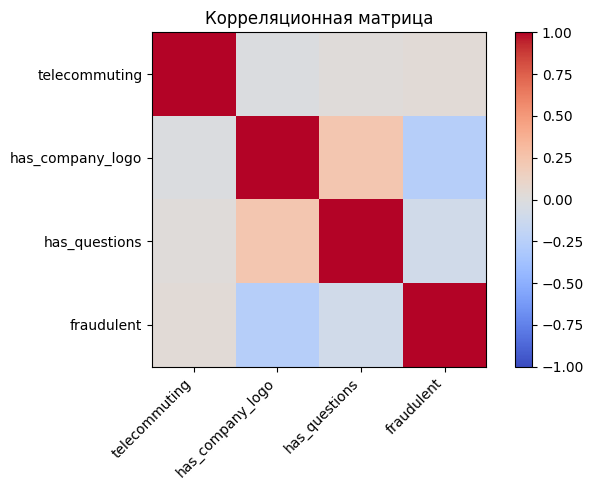

In [9]:
numeric_data = data.select_dtypes(include=np.number).drop(columns=["job_id"], errors="ignore")

if numeric_data.shape[1] > 1:
    corr = numeric_data.corr()
    display(corr)

    plt.figure(figsize=(7, 5))
    plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    plt.colorbar()
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.title("Корреляционная матрица")
    plt.tight_layout()
    plt.show()


Корреляция показывает, насколько линейно связаны числовые признаки. В этом датасете числовых столбцов мало, и большинство из них — индикаторы со значениями 0 или 1. Поэтому корреляционная матрица помогает посмотреть на связи между этими признаками.

## 8. Подготовка признаков

Для текста используем TF-IDF: слова превращаются в числовые признаки. Категориальные признаки закодируем с помощью One-Hot Encoding. `ColumnTransformer` нужен, чтобы разные типы столбцов обрабатывались по-разному.

In [10]:
text_columns = [c for c in ["title", "company_profile", "description", "requirements", "benefits"] if c in X.columns]
category_columns = [c for c in ["location", "department", "salary_range", "employment_type", "required_experience", "required_education", "industry", "function"] if c in X.columns]
binary_columns = [c for c in ["telecommuting", "has_company_logo", "has_questions"] if c in X.columns]

X = X.copy()
X["all_text"] = X[text_columns].fillna("").astype(str).agg(" ".join, axis=1)
X = X.drop(columns=text_columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

text_columns = ["all_text"]


In [11]:
text_transformer = TfidfVectorizer(max_features=20000, stop_words="english")
category_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = [("text", text_transformer, "all_text")]
if category_columns:
    transformers.append(("category", category_transformer, category_columns))
if binary_columns:
    transformers.append(("binary", SimpleImputer(strategy="most_frequent"), binary_columns))

preprocessor = ColumnTransformer(transformers)

## 9. Обучение модели и выбор параметра

Используем логистическую регрессию. Так как мошеннических объявлений намного меньше, чем настоящих, используем `class_weight="balanced"`, чтобы модель сильнее учитывала редкий класс.

In [12]:
model = Pipeline(steps=[
    ("preparation", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

parameters = {"classifier__C": [0.1, 1, 10]}
search = GridSearchCV(model, parameters, cv=3, scoring="f1", n_jobs=-1)
search.fit(X_train, y_train)

print("Лучший параметр:", search.best_params_)
print("Лучший F1 на кросс-валидации:", round(search.best_score_, 3))
best_model = search.best_estimator_


Лучший параметр: {'classifier__C': 10}
Лучший F1 на кросс-валидации: 0.784


## 10. Оценка качества

In [13]:
def show_scores(name, X_part, y_part):
    prediction = best_model.predict(X_part)
    print(name)
    print("Доля ошибок:", round(1 - accuracy_score(y_part, prediction), 3))
    print("Accuracy:", round(accuracy_score(y_part, prediction), 3))
    print("Precision:", round(precision_score(y_part, prediction, zero_division=0), 3))
    print("Recall:", round(recall_score(y_part, prediction, zero_division=0), 3))
    print("F1:", round(f1_score(y_part, prediction, zero_division=0), 3))
    print()
    return prediction

y_train_pred = show_scores("Обучающая выборка", X_train, y_train)
y_test_pred = show_scores("Тестовая выборка", X_test, y_test)


Обучающая выборка
Доля ошибок: 0.001
Accuracy: 0.999
Precision: 0.982
Recall: 1.0
F1: 0.991

Тестовая выборка
Доля ошибок: 0.013
Accuracy: 0.987
Precision: 0.864
Recall: 0.879
F1: 0.871



По результатам обучения на обучающей выборке получены `Accuracy = 0,999`, `Precision = 0,982`, `Recall = 1,000`, `F1 = 0,991`. На тестовой выборке значения ниже: `Accuracy = 0,987`, `Precision = 0,864`, `Recall = 0,879`, `F1 = 0,871`.

Тестовый результат можно считать хорошим для базовой модели: она находит примерно 88% мошеннических вакансий, а среди объявлений, которые она помечает как мошеннические, около 86% действительно относятся к этому классу. При этом модель пропускает часть мошеннических объявлений.

Между обучающей и тестовой выборками есть заметная разница: F1 снижается с `0,991` до `0,871`. Это может говорить о переобучении.

### Матрицы ошибок

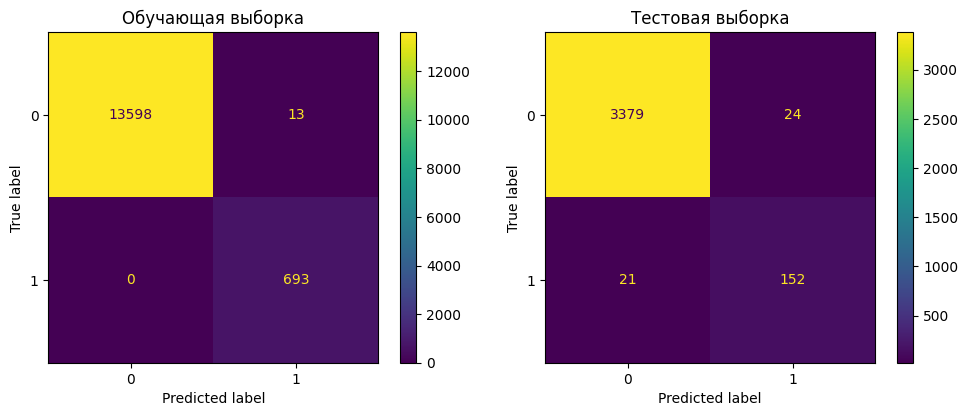

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred, ax=axes[0], values_format="d")
axes[0].set_title("Обучающая выборка")
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, ax=axes[1], values_format="d")
axes[1].set_title("Тестовая выборка")
plt.tight_layout()
plt.show()

В тестовой матрице ошибок строки — это настоящий класс, а столбцы — предсказанный. Для тестовой выборки получаются следующие результаты:

- **3 379** настоящих вакансий модель правильно признала настоящими;
- **24** настоящие вакансии модель ошибочно отметила как мошеннические;
- **21** мошенническую вакансию модель пропустила и признала настоящей;
- **152** мошеннические вакансии модель правильно обнаружила.

Худший сценарий - пропуск мошеннической вакансии. В тестовой выборке таких случаев 21, что составляет около 2,4% от всех настоящих вакансий.

## 11. Общие выводы

In [15]:
print("Размер датасета:", data.shape)
print("Доля мошеннических объявлений, %:", round(data["fraudulent"].mean() * 100, 2))
print("Лучший параметр модели:", search.best_params_)
print("F1 на обучающей выборке:", round(f1_score(y_train, y_train_pred, zero_division=0), 3))
print("F1 на тестовой выборке:", round(f1_score(y_test, y_test_pred, zero_division=0), 3))


Размер датасета: (17880, 18)
Доля мошеннических объявлений, %: 4.84
Лучший параметр модели: {'classifier__C': 10}
F1 на обучающей выборке: 0.991
F1 на тестовой выборке: 0.871


### Вывод

В работе была рассмотрена задача бинарной классификации: по данным вакансии нужно определить, является ли объявление настоящим или мошенническим. Датасет содержит 17 880 вакансий, при этом мошеннических объявлений только 4,84%. Также в некоторых столбцах много пропусков, особенно в зарплате и отделе компании. Поэтому пропуски были обработаны при подготовке данных, текстовые поля преобразованы с помощью TF-IDF, а категориальные признаки — с помощью One-Hot Encoding.

Для классификации использовалась логистическая регрессия. Среди проверенных значений параметра лучшим оказался `C = 10`, при этом F1 на кросс-валидации составил `0,784`. На тестовой выборке модель получила `Accuracy = 0,987` и `F1 = 0,871`, `Precision = 0,864`, `Recall = 0,879`. В тестовой выборке модель обнаружила 152 из 173 мошеннических вакансий, но пропустила 21 такую вакансию и ошибочно отметила 24 настоящие вакансии.

Результат показывает, что модель умеет находить большую часть мошеннических объявлений и заметно превосходит простую стратегию, при которой все объявления считаются настоящими. Однако качество на обучающей выборке (`F1 = 0,991`) существенно выше, чем на тестовой (`F1 = 0,871`), поэтому нельзя исключать переобучение. В дальнейшем можно попробовать другие модели и проверить, улучшится ли результат на тестовой выборке. Для этой задачи важно оценивать не только общую точность, но и то, сколько мошеннических вакансий модель пропускает.

**Датасет:** [Fake Job Posting Detection на Kaggle](https://www.kaggle.com/datasets/shivamb/real-or-fake-fake-jobposting-prediction).